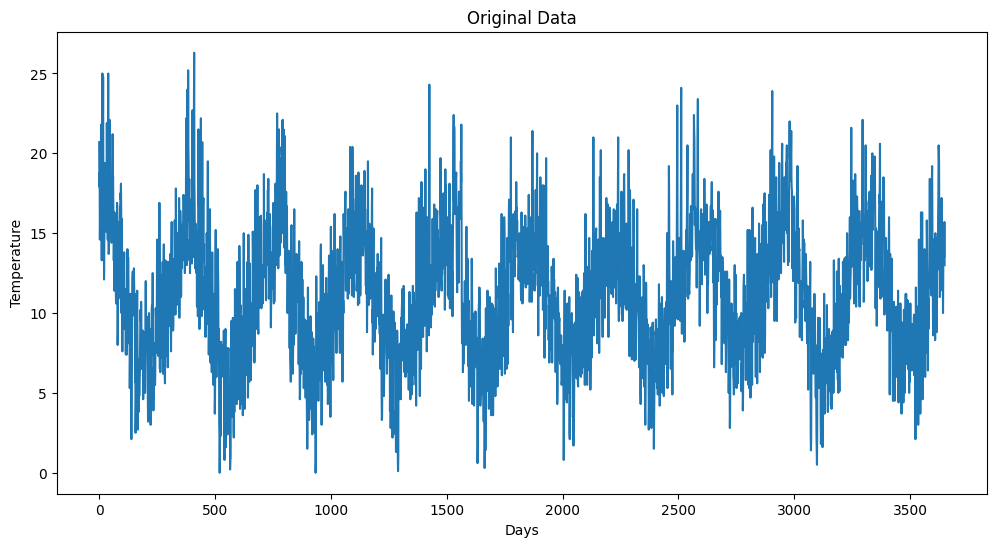

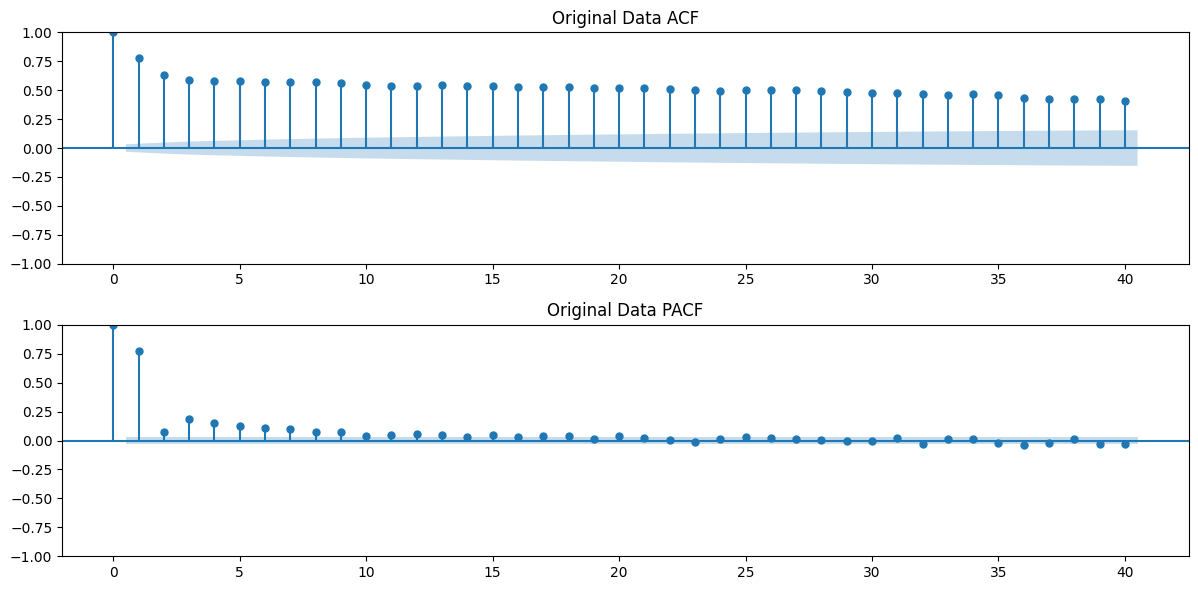

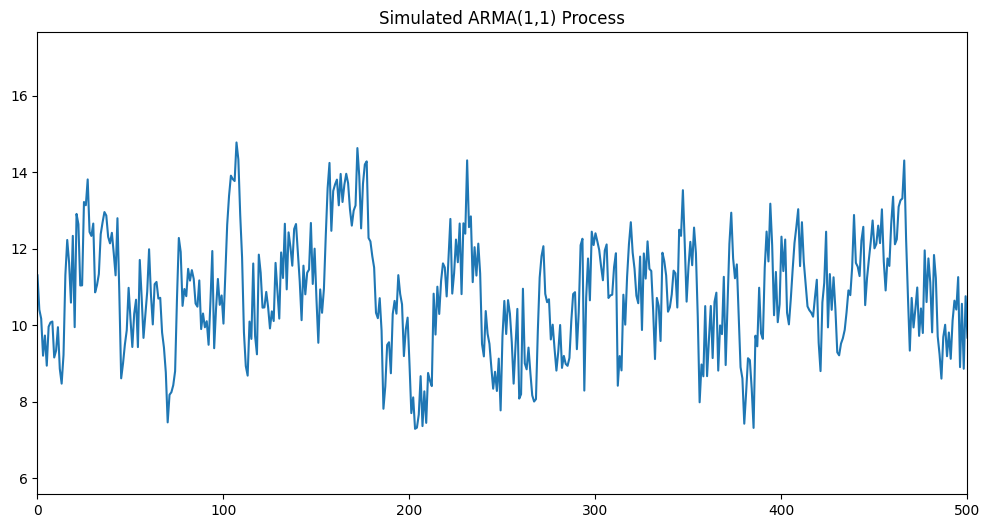

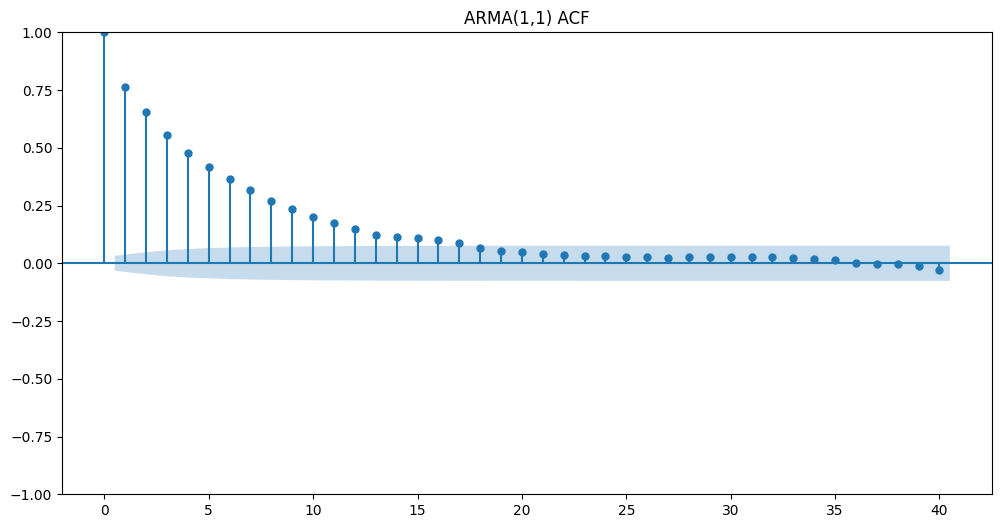

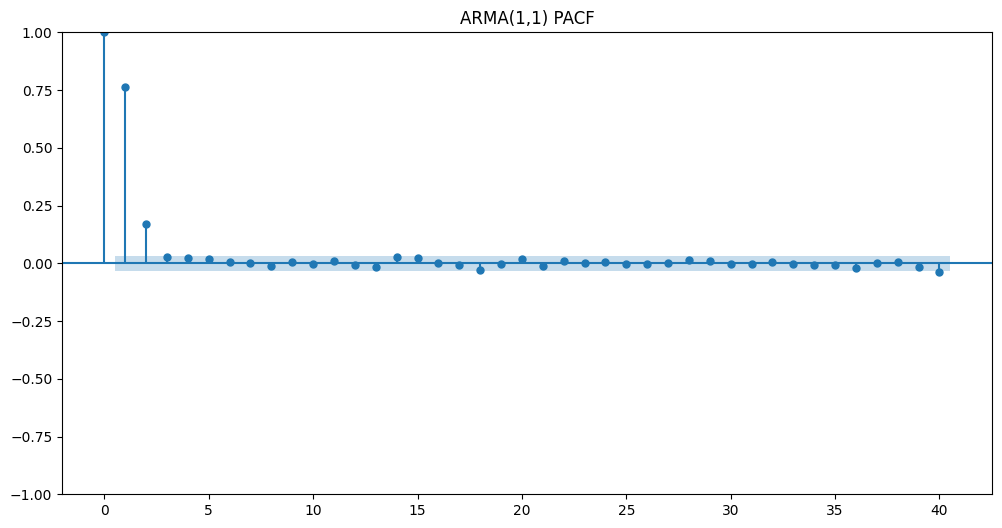

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


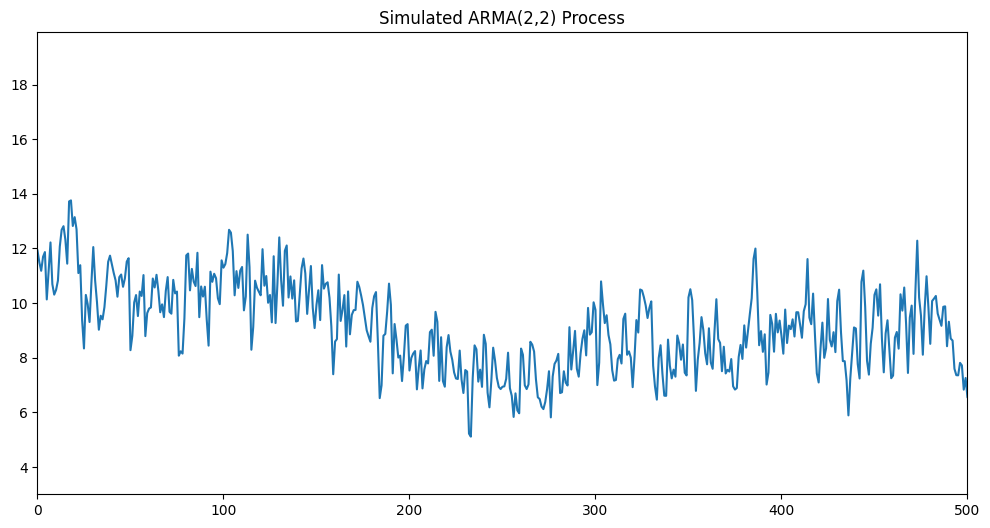

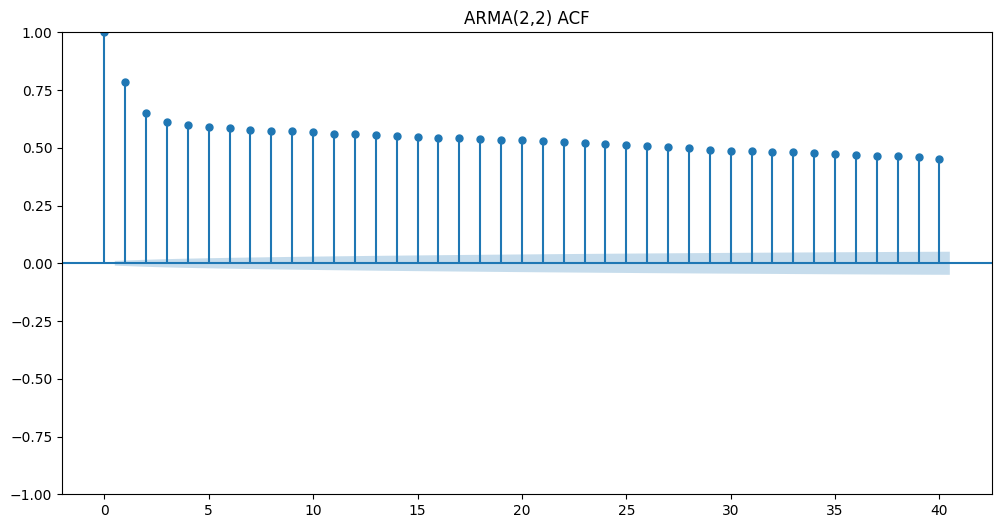

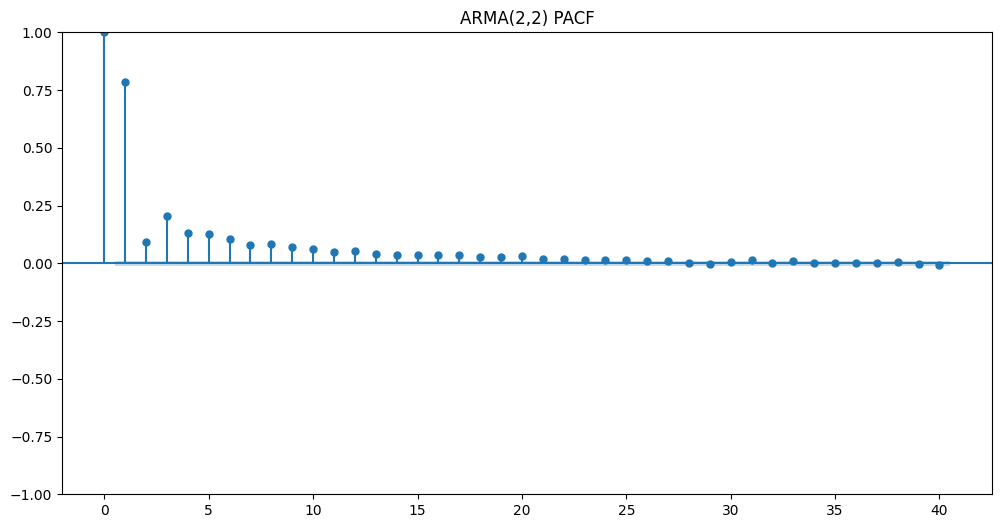

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Load dataset
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv'

data = pd.read_csv(url)

# Declare required variables
X = data['Temp']
N = len(X)

plt.rcParams['figure.figsize'] = [12, 6]

# Visualize original data
plt.plot(X)
plt.title('Original Data')
plt.xlabel('Days')
plt.ylabel('Temperature')
plt.show()

# Plot ACF and PACF for original data
plt.subplot(2, 1, 1)
plot_acf(X, lags=40, ax=plt.gca())
plt.title('Original Data ACF')

plt.subplot(2, 1, 2)
plot_pacf(X, lags=40, ax=plt.gca())
plt.title('Original Data PACF')

plt.tight_layout()
plt.show()

# Fitting ARMA(1,1) model
arma11_model = ARIMA(X, order=(1, 0, 1)).fit()

phi1_arma11 = arma11_model.arparams[0]
theta1_arma11 = arma11_model.maparams[0]

# Simulate ARMA(1,1) Process
ar1 = np.array([1, -phi1_arma11])
ma1 = np.array([1, theta1_arma11])

ARMA_1 = ArmaProcess(ar1, ma1).generate_sample(
    nsample=N,
    scale=np.sqrt(arma11_model.scale)
) + X.mean()

plt.plot(ARMA_1)
plt.title('Simulated ARMA(1,1) Process')
plt.xlim([0, 500])
plt.show()

# Plot ACF and PACF for ARMA(1,1)
plot_acf(ARMA_1, lags=40)
plt.title('ARMA(1,1) ACF')
plt.show()

plot_pacf(ARMA_1, lags=40)
plt.title('ARMA(1,1) PACF')
plt.show()

# Fitting ARMA(2,2) model
arma22_model = ARIMA(X, order=(2, 0, 2)).fit()

phi1_arma22 = arma22_model.arparams[0]
phi2_arma22 = arma22_model.arparams[1]

theta1_arma22 = arma22_model.maparams[0]
theta2_arma22 = arma22_model.maparams[1]

# Simulate ARMA(2,2) Process
ar2 = np.array([1, -phi1_arma22, -phi2_arma22])
ma2 = np.array([1, theta1_arma22, theta2_arma22])

ARMA_2 = ArmaProcess(ar2, ma2).generate_sample(
    nsample=N*10,
    scale=np.sqrt(arma22_model.scale)
) + X.mean()

plt.plot(ARMA_2)
plt.title('Simulated ARMA(2,2) Process')
plt.xlim([0, 500])
plt.show()

# Plot ACF and PACF for ARMA(2,2)
plot_acf(ARMA_2, lags=40)
plt.title('ARMA(2,2) ACF')
plt.show()

plot_pacf(ARMA_2, lags=40)
plt.title('ARMA(2,2) PACF')
plt.show()
